# Delayed feedback: a nonlinear OU process with a hard delay

**Showcases:** a hard delay $x(t-d)$ written directly in the drift. The tree level is the exact solution of the delay-differential equation; the loop corrections use Padé approximants of $e^{-i\omega d}$ with the order chosen automatically.

$$\dot x = -\mu x - c\,x(t-d) - \varepsilon x^3 + \xi, \qquad \langle\xi(t)\xi(t')\rangle = 2D\,\delta(t-t').$$

The delayed negative feedback makes the autocorrelation oscillate with a period of about $4d$ at these parameters.

In [1]:
%matplotlib inline
try:
    preparser(False)   # Sage kernel: plain Python syntax and numbers in the cells below
except NameError:
    pass
import os, sys, time, warnings
import numpy as np
import matplotlib.pyplot as plt
# locate the repository root (the folder holding the 'api' package) from any working directory
_root = os.path.abspath('')
while _root != os.path.dirname(_root) and not os.path.isdir(os.path.join(_root, 'api')):
    _root = os.path.dirname(_root)
sys.path.insert(0, _root)
os.chdir(_root)
def ells(r):   # C(tau) per loop order (real parts), a list indexed by the loop order
    return [np.real(np.asarray(r['C_tau_by_ell'][l])) for l in sorted(r['C_tau_by_ell'])]
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

In [2]:
from api.sde import SDE
from api.noise import Gaussian
from api.delay import Kernel
from api import compute_cumulants

def delay_report(r):
    d = r.get('delay') or {}
    return {k: d.get(k) for k in ('tree', 'approximant', 'n', 'orders_run', 'target_met') if k in d}

## 1. The model and the pipeline

In [3]:
P = dict(mu=1.0, c=0.6, d=1.0, eps=0.03, D=0.5)
m = (SDE('delayed OU')
     .parameter('mu', default=P['mu'], domain='positive').parameter('c', default=P['c'])
     .parameter('d', default=P['d'], domain='positive')
     .parameter('eps', default=P['eps'], domain='positive').parameter('D', default=P['D'], domain='positive')
     .field('x')
     .drift('x', '-mu*x - c*x(t - d) - eps*x^3')
     .noise('xi', Gaussian(var='2*D'), couples={'x': 1}))
m.show()
tau = np.linspace(-8, 8, 65)
t0 = time.time()
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    res = compute_cumulants(m.build(), k=2, max_ell=1, external_fields=[('x', 1), ('x', 1)],
                            tau_grid=tau, parallel=False, verbose=False, delay={'tol': 1e-4})
print(f"{time.time() - t0:.0f} s; delay:", delay_report(res))
C = ells(res)

# SDE 'delayed OU' (ito)
.set_action_text('''
sum(
    xt[i]*(Dt*x[i] - (-mu*x[i] - c*Conv(delay_d, x[i]) - eps*x[i]^3))
    - (D*xt[i]^2)
    for i in pop)
''')
.equation(lhs='Dt*x[i] + mu*x[i]', rhs='-eps*x[i]^3 - c*((1))*(x[i])', population='pop')
# note: mean-field equation of 'x': linear term -mu*x[i] moved to the lhs.
3 s; delay: {'tree': 'exact', 'approximant': 'pade', 'n': 8, 'orders_run': [4, 8], 'target_met': True}


## 2. Independent simulation

Euler–Maruyama with a ring buffer holding the last $d/\mathrm dt$ values; several independent long runs give the error bars. Not part of the pipeline.

In [4]:
from numba import njit

def autocov(series_list, max_lag):
    # connected autocovariance from several independent runs (mean removed per run); mean and SE over runs
    out = []
    for s in series_list:
        s = s - s.mean()
        n = len(s); f = np.fft.rfft(s, 2 * n)
        ac = np.fft.irfft(f * np.conj(f))[:max_lag + 1] / (n - np.arange(max_lag + 1))
        out.append(ac)
    out = np.array(out)
    return out.mean(0), out.std(0, ddof=1) / np.sqrt(len(out))

@njit(cache=False)
def sim(n_steps, dt, mu, c, d, eps, D, every, seed):
    np.random.seed(seed)
    lag = int(d / dt + 0.5); buf = np.zeros(lag); p = 0
    x = 0.0; sq = np.sqrt(2.0 * D * dt)
    out = np.empty(n_steps // every)
    for k in range(n_steps + 20000):
        xd = buf[p]
        x_new = x + dt * (-mu * x - c * xd - eps * x ** 3) + sq * np.random.randn()
        buf[p] = x; p = (p + 1) % lag
        x = x_new
        j = k - 20000
        if j >= 0 and j % every == 0 and j // every < out.shape[0]:
            out[j // every] = x
    return out

dt, every, T = 0.005, 10, 2.0e5                     # samples every 0.05
t0 = time.time()
runs = [sim(int(T / dt), dt, P['mu'], P['c'], P['d'], P['eps'], P['D'], every, s) for s in range(8)]
lags = np.arange(0, 161, 4)                          # up to tau = 8
ac, se = autocov(runs, lags[-1])
ac, se = ac[lags], se[lags]
print(f"simulation {time.time() - t0:.0f} s")

simulation 10 s


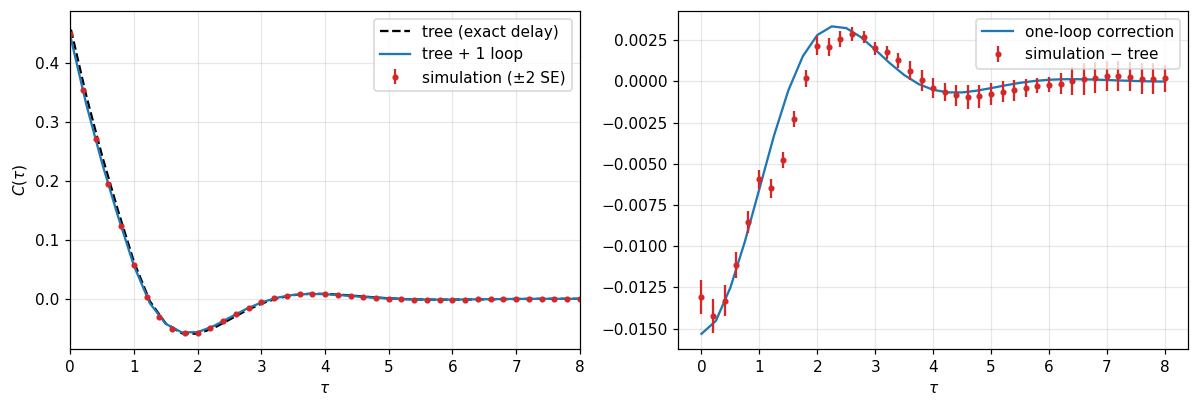

C(0): tree 0.4622, tree + 1 loop 0.4469, simulation 0.4491 +- 0.0005


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(tau, C[0], 'k--', label='tree (exact delay)')
ax[0].plot(tau, C[0] + C[1], 'C0', label='tree + 1 loop')
ax[0].errorbar(lags * dt * every, ac, yerr=2 * se, fmt='o', ms=3, color='C3', label='simulation (±2 SE)')
ax[0].set_xlim(0, 8); ax[0].set_xlabel(r'$\tau$'); ax[0].set_ylabel(r'$C(\tau)$'); ax[0].legend()
pos = tau >= 0
ax[1].plot(tau[pos], C[1][pos], 'C0', label='one-loop correction')
ax[1].errorbar(lags * dt * every, ac - np.interp(lags * dt * every, tau, C[0]), yerr=2 * se, fmt='o', ms=3,
               color='C3', label='simulation − tree')
ax[1].set_xlabel(r'$\tau$'); ax[1].legend()
plt.tight_layout(); plt.show()
i0 = len(tau) // 2
print(f"C(0): tree {C[0][i0]:.4f}, tree + 1 loop {C[0][i0] + C[1][i0]:.4f}, simulation {ac[0]:.4f} +- {se[0]:.4f}")

The right panel isolates the loop correction: the cubic nonlinearity lowers the variance and shifts the oscillation, and the simulation residual follows the one-loop curve. The one-loop correction (−0.0153, 3.3 % of the tree variance) slightly overshoots the simulated shift (−0.0131); the remaining 0.5 % (0.4469 against 0.4491 ± 0.0005) is the size expected from the two-loop term, $O(\varepsilon^2)$, plus the $O(\mathrm dt)$ Euler bias of the simulation. At $\varepsilon = 0.1$ the same comparison leaves a 2.7 % gap, again the size of the two-loop term, which is why the coupling is kept small here.